# Practical Work 3 — Data Preprocessing and Pipelines

**Project:** MACHINEGUARD  
**Level:** C

## Objective

To develop a reproducible preprocessing pipeline using Scikit-learn, implement a custom transformer, test the pipeline on new data, and evaluate preprocessing performance.

In [11]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from pathlib import Path

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

print("MACHINEGUARD - Practical Work 3")
print("All libraries imported successfully!")


MACHINEGUARD - Practical Work 3
All libraries imported successfully!


In [12]:

project_dir = Path.cwd().resolve()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

df = pd.read_csv(
    project_dir / "data" / "raw" / "ai4i2020.csv"
)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [13]:

feature_columns = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[feature_columns].copy()
y = df["Machine failure"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)


Training set: (8000, 6)
Testing set: (2000, 6)


In [14]:

class TemperatureDifferenceTransformer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        required_columns = [
            "Air temperature [K]",
            "Process temperature [K]"
        ]

        for column in required_columns:
            if column not in X.columns:
                raise ValueError(f"Missing column: {column}")

        return self

    def transform(self, X):
        X = X.copy()

        X["Temperature difference [K]"] = (
            X["Process temperature [K]"]
            - X["Air temperature [K]"]
        )

        return X


temperature_transformer = TemperatureDifferenceTransformer()

X_train_transformed = temperature_transformer.fit_transform(X_train)

display(X_train_transformed.head())


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperature difference [K]
4058,M,302.0,310.9,1456,47.2,54,8.9
1221,M,297.0,308.3,1399,46.4,132,11.3
6895,M,301.0,311.6,1357,45.6,137,10.6
9863,L,298.9,309.8,1411,56.3,84,10.9
8711,L,297.1,308.5,1733,28.7,50,11.4


In [15]:

numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Temperature difference [K]"
]

categorical_features = ["Type"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

full_pipeline = Pipeline([
    ("temperature_difference", TemperatureDifferenceTransformer()),
    ("preprocessing", preprocessor)
])

X_train_ready = full_pipeline.fit_transform(X_train)
X_test_ready = full_pipeline.transform(X_test)

print("Training data:", X_train_ready.shape)
print("Testing data:", X_test_ready.shape)


Training data: (8000, 9)
Testing data: (2000, 9)


In [16]:

new_data_1 = pd.DataFrame({
    "Type": ["L"],
    "Air temperature [K]": [300.0],
    "Process temperature [K]": [310.0],
    "Rotational speed [rpm]": [1500],
    "Torque [Nm]": [40.0],
    "Tool wear [min]": [100]
})

result_1 = temperature_transformer.transform(new_data_1)

assert result_1["Temperature difference [K]"].iloc[0] == 10.0

print("Test 1 passed!")

new_data_2 = new_data_1.copy()
new_data_2["Type"] = "UNKNOWN"

result_2 = full_pipeline.transform(new_data_2)

assert result_2.shape == (1, 9)

print("Test 2 passed!")


Test 1 passed!
Test 2 passed!


In [17]:

dataset_sizes = [10000, 50000, 100000]
execution_times = []

for size in dataset_sizes:
    synthetic_data = X_train.sample(
        n=size,
        replace=True,
        random_state=42
    ).reset_index(drop=True)

    start = time.perf_counter()

    full_pipeline.transform(synthetic_data)

    elapsed = time.perf_counter() - start
    execution_times.append(elapsed)

    print(f"Rows: {size}, Time: {elapsed:.4f} seconds")


Rows: 10000, Time: 0.0056 seconds
Rows: 50000, Time: 0.0112 seconds
Rows: 100000, Time: 0.0238 seconds


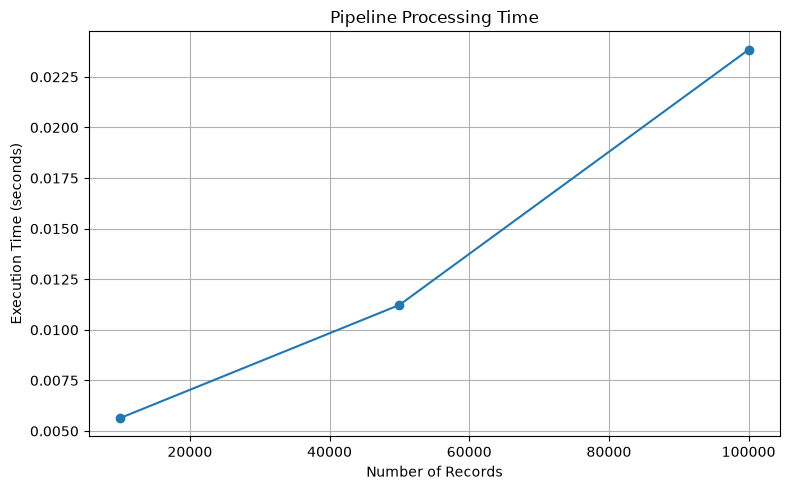

In [18]:

plt.figure(figsize=(8, 5))

plt.plot(dataset_sizes, execution_times, marker="o")

plt.title("Pipeline Processing Time")
plt.xlabel("Number of Records")
plt.ylabel("Execution Time (seconds)")
plt.grid(True)

plt.tight_layout()
plt.show()


## Performance Analysis

The preprocessing pipeline was evaluated using datasets of 10,000, 50,000, and 100,000 records.

The datasets were expanded by sampling existing training observations with replacement. This increases the number of rows but does not generate independent new observations.

The experiment measures preprocessing time and helps evaluate pipeline scalability.

Potential bottlenecks include DataFrame copying, imputation, scaling, and categorical encoding.

## Final Conclusions

A reproducible preprocessing pipeline was developed for the MACHINEGUARD project.

The dataset was divided into training and testing sets before fitting preprocessing components.

A custom transformer was implemented using BaseEstimator and TransformerMixin to calculate temperature differences.

The transformer was integrated into a Scikit-learn Pipeline with missing-value imputation, feature scaling, and categorical encoding.

Two tests confirmed that the pipeline can process new data and handle unknown categories.

The performance experiment evaluated how preprocessing time changes with increasing dataset size.

The resulting pipeline can be reused for subsequent machine learning experiments.